# B-8802B · engenharia de features e menos sensores no modelo de anomalia

**Pergunta.** O erro de reconstrução do VAE oscila e sobe em 2026. Dá para deixá-lo mais estável (menos efeito da
estação na temperatura) sem perder a detecção? Que variáveis causam isso? Ajuda tirar a temperatura, transformá-la
(variação no tempo, nível relativo), usar só vibração, só temperatura, ou acrescentar espectro?

**Como foi feito** (`scripts/fe_exploracao_b8802b.py`, `scripts/fe_exploracao_termica.py`; este notebook só lê os
resultados):
- mesmo filtro de operação do bundle, treino em 2025, mesma arquitetura do VAE de produção (128-64-32, latente 16);
- 7 variantes de entrada × 6 modelos (2 taxas de aprendizado × 3 sementes) — sempre olhar o grupo, não um modelo só;
- mesma régua de alarme do deploy: limiar μ+6,5σ do erro em 2025, 15 de 20 leituras em 100 min, alerta ≥ 1 h;
- cada modelo com o score **bruto** e **suavizado** (mediana móvel de 1 h).

**Bateria:** alertas em 2025/2026, episódio de 17/01/2026 (âncora conhecida), falha real de 2022, falha sintética
com a assinatura de 2022 em 3 datas de 2026 (100% e 50%) e uma falha **só térmica** (temperatura sobe, vibração não).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts"))
import fe_exploracao_b8802b as fx

R = RAIZ / "results/fe_exploracao"
av = pd.read_csv(R / "avaliacao.csv"); ep = pd.read_csv(R / "episodios.csv"); te = pd.read_csv(R / "termica.csv")
NOMES = {"base": "base (5 sensores, como produção)", "vib": "só vibração", "vib_press": "vibração + pressões",
         "temp_delta": "vib+press + ΔT 30 min/2 h", "temp_rel": "vib+press + T − mediana 3 d",
         "temps": "só temperaturas", "espectro": "base + espectro/desvio das vibrações"}
CORES = {"base": "#2a78d6", "vib": "#eda100", "vib_press": "#1baf7a", "temp_delta": "#eb6834",
         "temp_rel": "#8a5cd1", "temps": "#b8336a", "espectro": "#8a897f"}
plt.rcParams.update({"font.size": 11})
def estilo(ax, t):
    ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

## 1. De onde vem o erro do modelo de produção

Erro de reconstrução do bundle B-8802B-2025 separado por sensor (cada barra é a média do mês; a soma é o erro que vai
para o alarme).

,% do erro em 2025,% do erro em 2026
Pressão Sucção,21.0,12.0
Pressão Descarga,18.0,14.0
Vibração Bomba LA,21.0,19.0
Vibração Bomba LNA,21.0,24.0
Temperatura Bomba LA,20.0,32.0


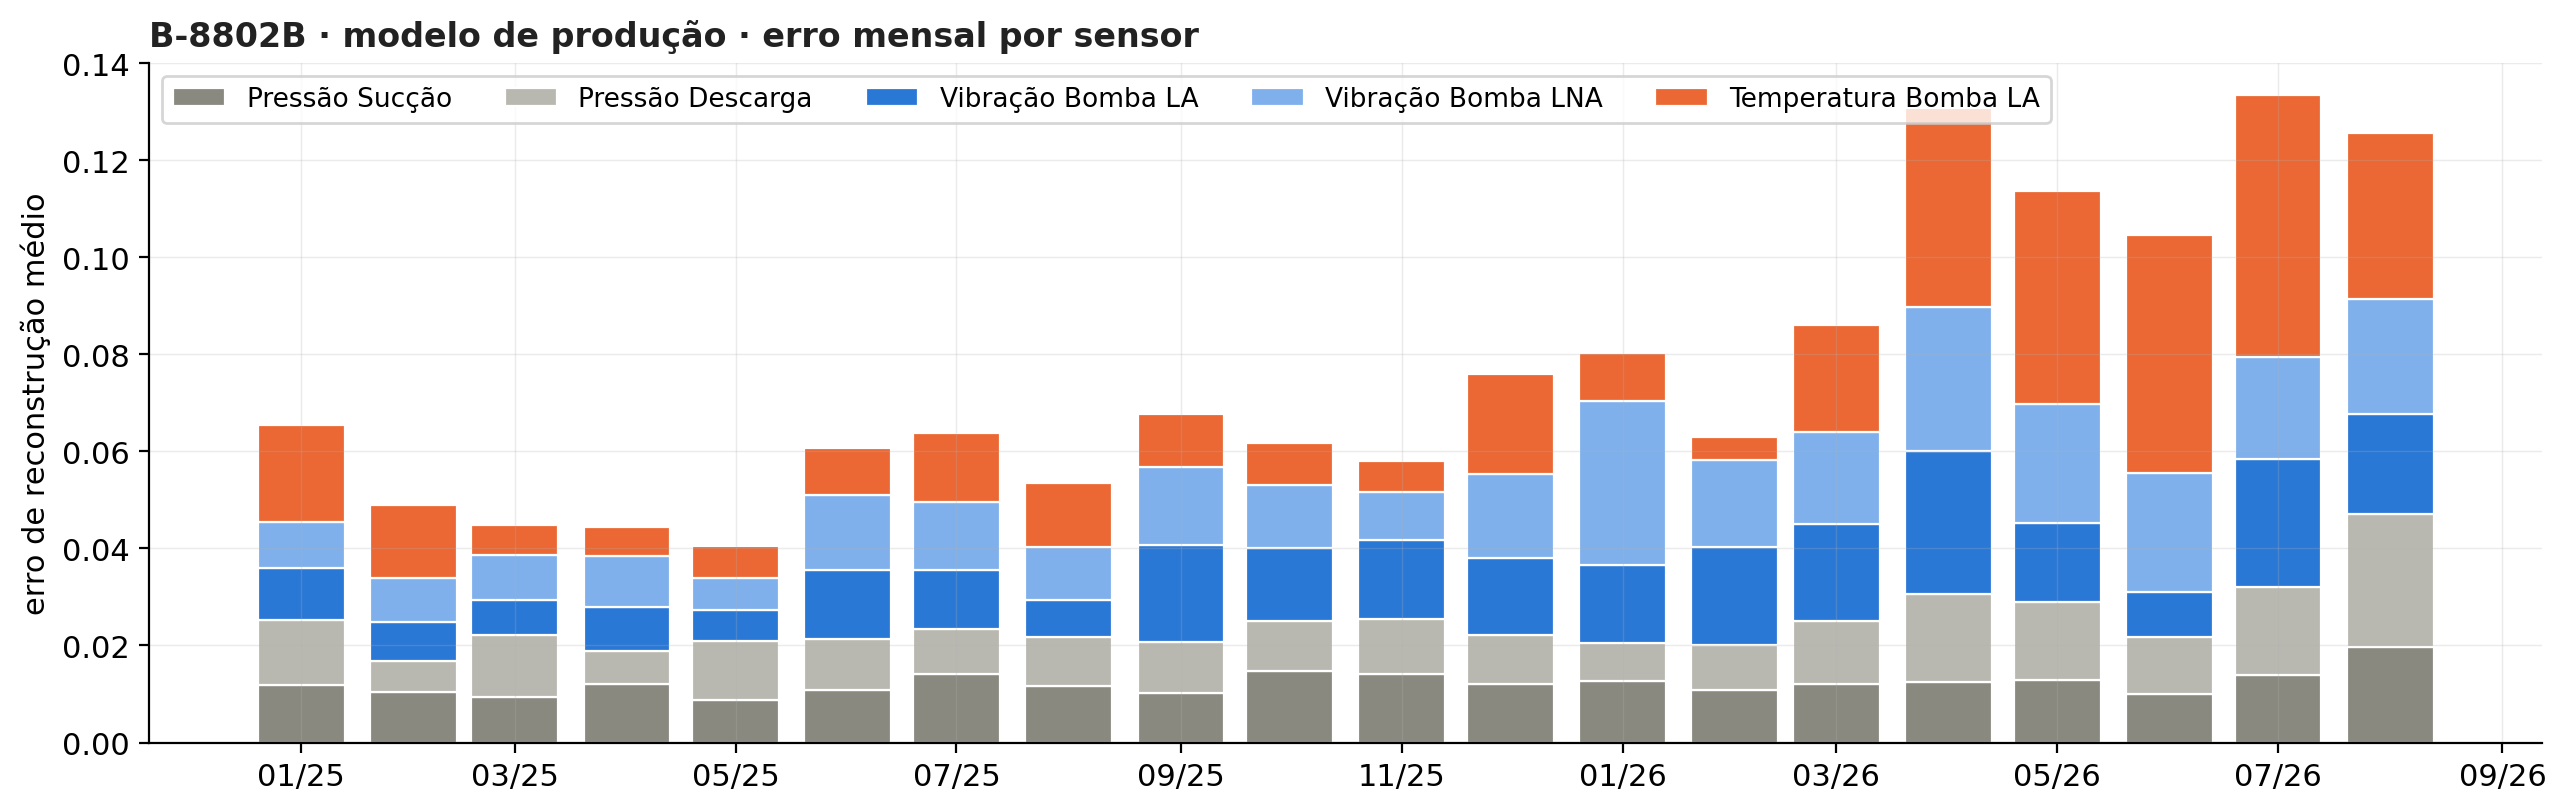

In [2]:
si = fx.si; b = fx.BUNDLE
raw = si.carregar_dados(fx.CFG["data_new"])
X = si.preprocessar(b, raw); m = si.carregar_modelo(b)
with torch.no_grad():
    x = torch.tensor(X.values, dtype=torch.float32); r = m(x)[0]
S = pd.DataFrame(((r - x) ** 2).numpy() / X.shape[1], index=X.index, columns=X.columns)
mes = S.resample("MS").mean()
cores_s = ["#8a897f", "#b9b8b0", "#2a78d6", "#7fb0ec", "#eb6834"]
fig, ax = plt.subplots(figsize=(13, 4.2))
base_ = np.zeros(len(mes))
for c, cor in zip(mes.columns, cores_s):
    ax.bar(mes.index, mes[c], bottom=base_, width=24, color=cor, label=c, edgecolor="white", lw=0.8)
    base_ += mes[c].values
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax.set_ylabel("erro de reconstrução médio")
ax.legend(ncol=5, fontsize=9.5, loc="upper left")
estilo(ax, "B-8802B · modelo de produção · erro mensal por sensor")
fig.tight_layout()

parc = pd.DataFrame({p: (S.loc[p].sum() / S.loc[p].values.sum() * 100).round(0) for p in ["2025", "2026"]})
parc.columns = ["% do erro em 2025", "% do erro em 2026"]; parc

**Leitura:** em 2025 cada sensor responde por ~20% do erro. Em abr–ago/2026 o erro total dobra e a parcela da
**temperatura do mancal LA** fica ~9× maior (o mancal esfriou para ~45 °C, abaixo do que o treino viu): a suspeita do
efeito sazonal da temperatura se confirma. Correlação do erro com o nível da temperatura: −0,35 (mais frio → mais erro).

## 2. Resumo por variante (mediana dos 6 modelos)

- **erro 2026/2025**: erro médio em abr–ago/2026 ÷ erro médio em 2025 (1 = estável; quanto maior, mais o modelo "estranha"
  2026 sem que nada tenha quebrado);
- **oscilação**: desvio da variação de 5 em 5 min ÷ desvio do score;
- **âncora 17/01**: quantos dos 6 modelos alertam no episódio conhecido de 17/01/2026;
- **sintética**: casos detectados antes do fim da rampa / casos válidos, somando os 6 modelos (100% e 50% de intensidade).

In [3]:
s100 = [c for c in av if c.startswith("sint100")]; s50 = [c for c in av if c.startswith("sint50")]
av["s100_ok"] = (av[s100] > 0).sum(axis=1); av["s100_n"] = av[s100].notna().sum(axis=1)
av["s50_ok"] = (av[s50] > 0).sum(axis=1); av["s50_n"] = av[s50].notna().sum(axis=1)
av["s100_h"] = av[s100].where(av[s100] > -99).median(axis=1)
g = av.merge(ep[["variante", "cand", "modo", "ancora_17jan"]], on=["variante", "cand", "modo"])
res = g.groupby(["variante", "modo"]).agg(
    entradas=("n_entradas", "first"), erro_26_25=("erro_2026T2T3/2025", "median"), oscilacao=("rugosidade", "median"),
    alerta_janmai26=("alerta_jan-mai26_%", "median"), alerta_junago26=("alerta_jun-ago26_%", "median"),
    episodios_2026=("episodios_2026", "median"), ancora=("ancora_17jan", "sum"),
    falha2022_d=("falha2022_dias", "median"), s100_ok=("s100_ok", "sum"), s100_n=("s100_n", "sum"),
    s50_ok=("s50_ok", "sum"), s50_n=("s50_n", "sum"), antecedencia_h=("s100_h", "median"))
tab = pd.DataFrame({
    "entradas": res.entradas, "erro 2026/2025": res.erro_26_25.round(2), "oscilação": res.oscilacao.round(2),
    "alerta jan–mai/26 (%)": res.alerta_janmai26.round(3), "alerta jun–ago/26 (%)": res.alerta_junago26.round(3),
    "episódios 2026": res.episodios_2026, "âncora 17/01": res.ancora.astype(str) + "/6",
    "falha 2022 (dias)": res.falha2022_d.round(1),
    "sintética 100%": res.s100_ok.astype(str) + "/" + res.s100_n.astype(str),
    "sintética 50%": res.s50_ok.astype(str) + "/" + res.s50_n.astype(str),
    "antecedência sintética (h)": res.antecedencia_h.round(0)})
tab.index = [f"{NOMES[v]} · {m}" for v, m in tab.index]
tab

,entradas,erro 2026/2025,oscilação,alerta jan–mai/26 (%),alerta jun–ago/26 (%),episódios 2026,âncora 17/01,falha 2022 (dias),sintética 100%,sintética 50%,antecedência sintética (h)
"base (5 sensores, como produção) · bruto",5,1.79,0.68,0.037,0.000,1.0,4/6,2.1,18/18,11/18,21.0
"base (5 sensores, como produção) · suave",5,1.92,0.16,0.201,0.005,4.0,6/6,2.1,17/17,12/17,23.0
base + espectro/desvio das vibrações · bruto,13,2.77,0.32,0.072,1.083,10.5,0/6,2.1,3/12,0/12,-12.0
base + espectro/desvio das vibrações · suave,13,2.79,0.10,0.916,3.227,41.5,0/6,2.1,9/12,1/12,10.0
vib+press + ΔT 30 min/2 h · bruto,6,1.09,0.72,0.004,0.000,0.5,3/6,2.0,8/18,2/18,4.0
vib+press + ΔT 30 min/2 h · suave,6,1.11,0.18,0.115,0.022,3.0,6/6,2.1,18/18,12/18,21.0
vib+press + T − mediana 3 d · bruto,5,1.12,0.73,0.080,0.000,2.5,5/6,2.1,15/18,10/18,19.0
vib+press + T − mediana 3 d · suave,5,1.16,0.18,0.303,0.000,4.0,6/6,2.1,16/18,14/18,22.0
só temperaturas · bruto,4,3.94,0.13,0.551,0.180,9.5,1/6,2.0,0/18,0/18,-22.0
só temperaturas · suave,4,3.95,0.07,0.583,0.222,12.0,1/6,2.0,0/17,0/17,-20.0


## 3. O erro fica estável em 2026?

Erro mensal ÷ erro médio de 2025, um modelo por variante (semente 0, taxa 1e-4, score bruto). Linha em 1 = o modelo
vê 2026 como viu 2025.

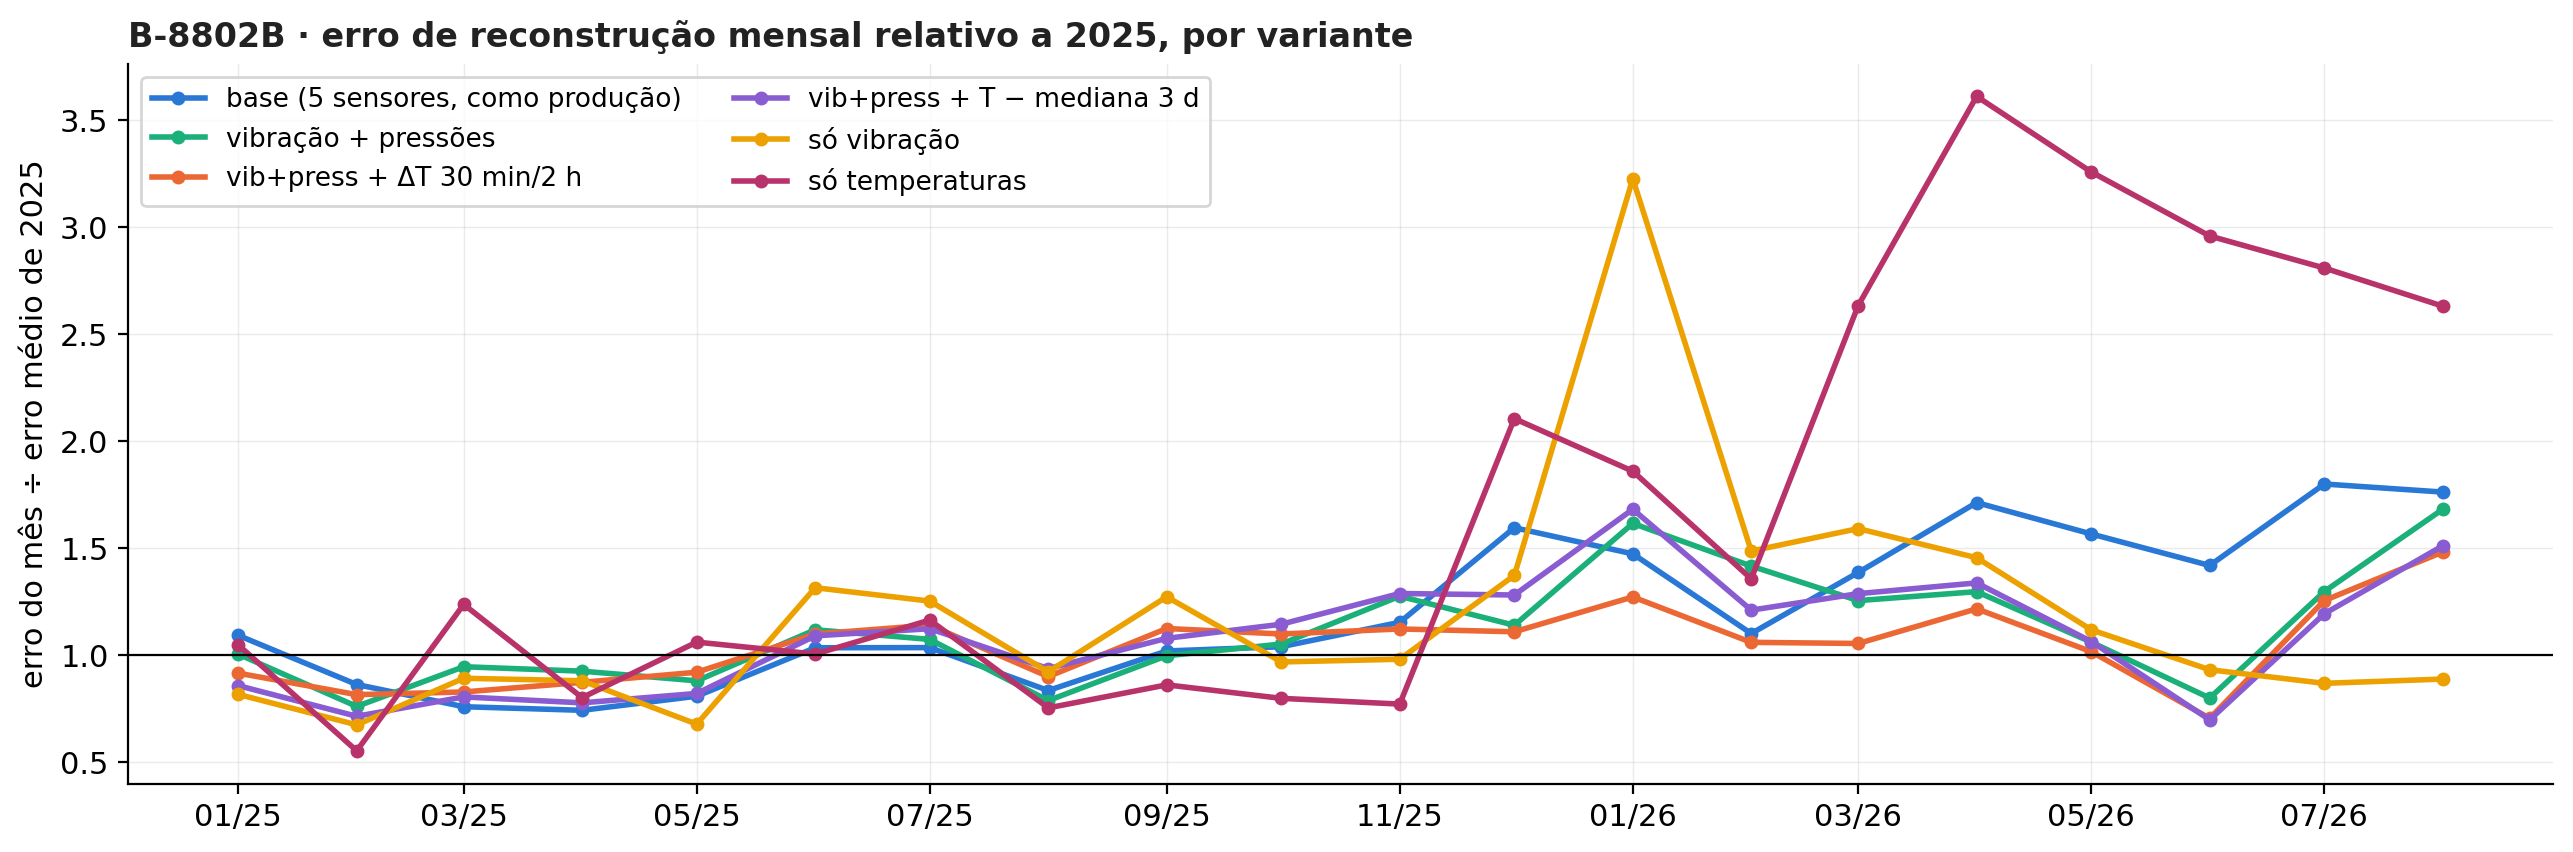

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.4))
for v in ["base", "vib_press", "temp_delta", "temp_rel", "vib", "temps"]:
    e = pd.read_parquet(R / "scores" / f"{v}__l128-64-32_lat16_lr0.0001_s0.parquet").score
    mm = e.resample("MS").mean() / e.loc["2025"].mean()
    ax.plot(mm.index, mm.values, marker="o", ms=4, lw=2, color=CORES[v], label=NOMES[v])
ax.axhline(1, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax.set_ylabel("erro do mês ÷ erro médio de 2025")
ax.legend(fontsize=9.5, ncol=2)
estilo(ax, "B-8802B · erro de reconstrução mensal relativo a 2025, por variante")
fig.tight_layout()

**Leitura:** base e "só temperaturas" sobem junto com o esfriamento de abr–jul/2026; as variantes sem o nível da
temperatura ficam perto de 1. Em ago/2026 todas sobem para ~1,5×: aí o erro vem da pressão de descarga (ver a figura
da seção 1), não da temperatura. "Só vibração" tem o pico de jan/2026 (episódios de 10–17/01).

## 4. Suavizar o score (mediana móvel de 1 h)

Uma semana de abril/2026, modelo base: o score bruto e o suavizado, cada um com o seu limiar (μ+6,5σ de 2025).

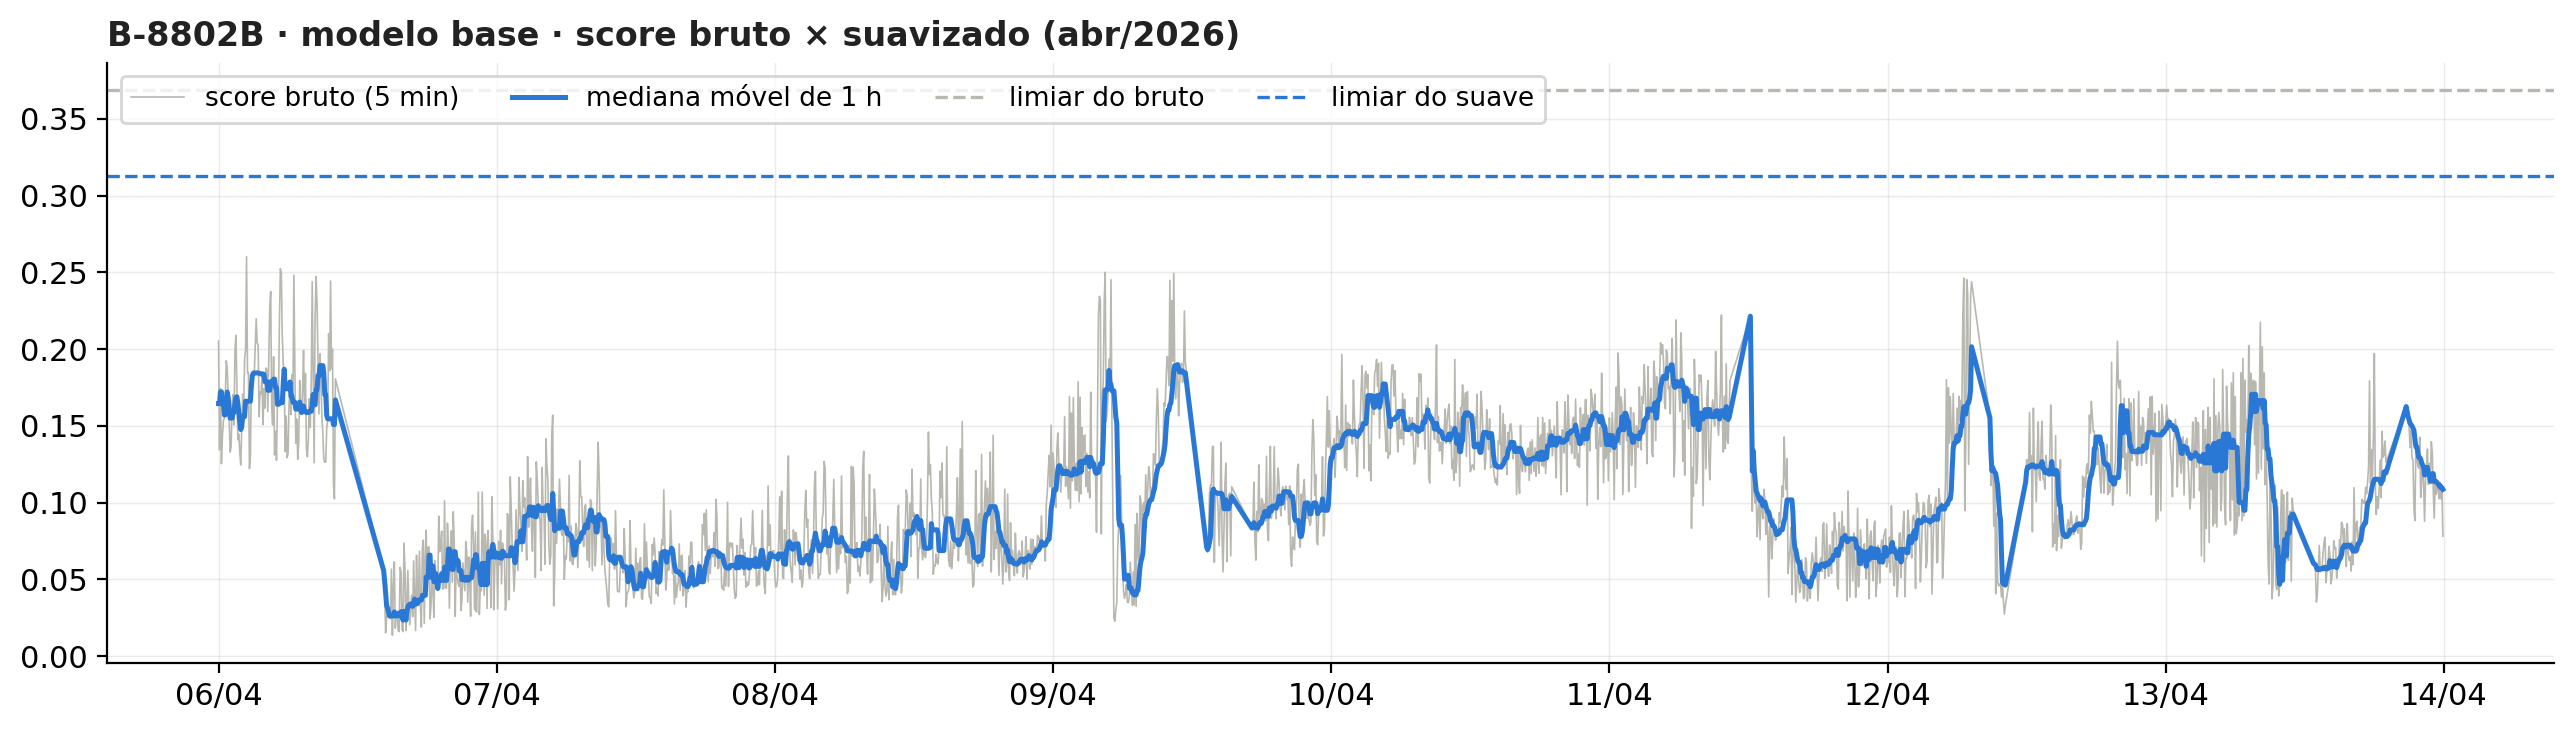

In [5]:
e = pd.read_parquet(R / "scores" / "base__l128-64-32_lat16_lr0.0001_s0.parquet").score
sm = fx.suavizar(e)
thr = {k: s.loc["2025"].mean() + 6.5 * s.loc["2025"].std() for k, s in [("bruto", e), ("suave", sm)]}
w = slice("2026-04-06", "2026-04-13")
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(e.loc[w].index, e.loc[w].values, lw=0.6, color="#b9b8b0", label="score bruto (5 min)")
ax.plot(sm.loc[w].index, sm.loc[w].values, lw=1.8, color="#2a78d6", label="mediana móvel de 1 h")
ax.axhline(thr["bruto"], color="#b9b8b0", ls="--", lw=1.2, label="limiar do bruto")
ax.axhline(thr["suave"], color="#2a78d6", ls="--", lw=1.2, label="limiar do suave")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(fontsize=9.5, ncol=4, loc="upper left")
estilo(ax, "B-8802B · modelo base · score bruto × suavizado (abr/2026)")
fig.tight_layout()

**Leitura:** a mediana de 1 h tira ~75% da oscilação (coluna "oscilação" cai de ~0,7 para ~0,16) e o gráfico fica
muito mais legível. Mas, com o limiar recalculado como μ+6,5σ, o desvio do score suave é menor e o limiar desce junto:
o número de episódios em 2026 **sobe** (base: 1 → 4) e a detecção fica parecida. Suavizar serve para a visualização e
para a operação ler a tendência; para alarmar menos, o limiar do score suave precisa ser calibrado de outro jeito
(por exemplo, pelo mesmo número de alertas em 2025), não por μ+6,5σ.

## 5. Alerta × sensibilidade, modelo a modelo

Cada ponto é um modelo (score bruto): episódios de alerta em 2026 (sem falha conhecida, exceto a âncora de 17/01) ×
casos da falha sintética detectados antes do fim da rampa (100% e 50%, de 6 possíveis). O ideal é o canto **superior
esquerdo**.

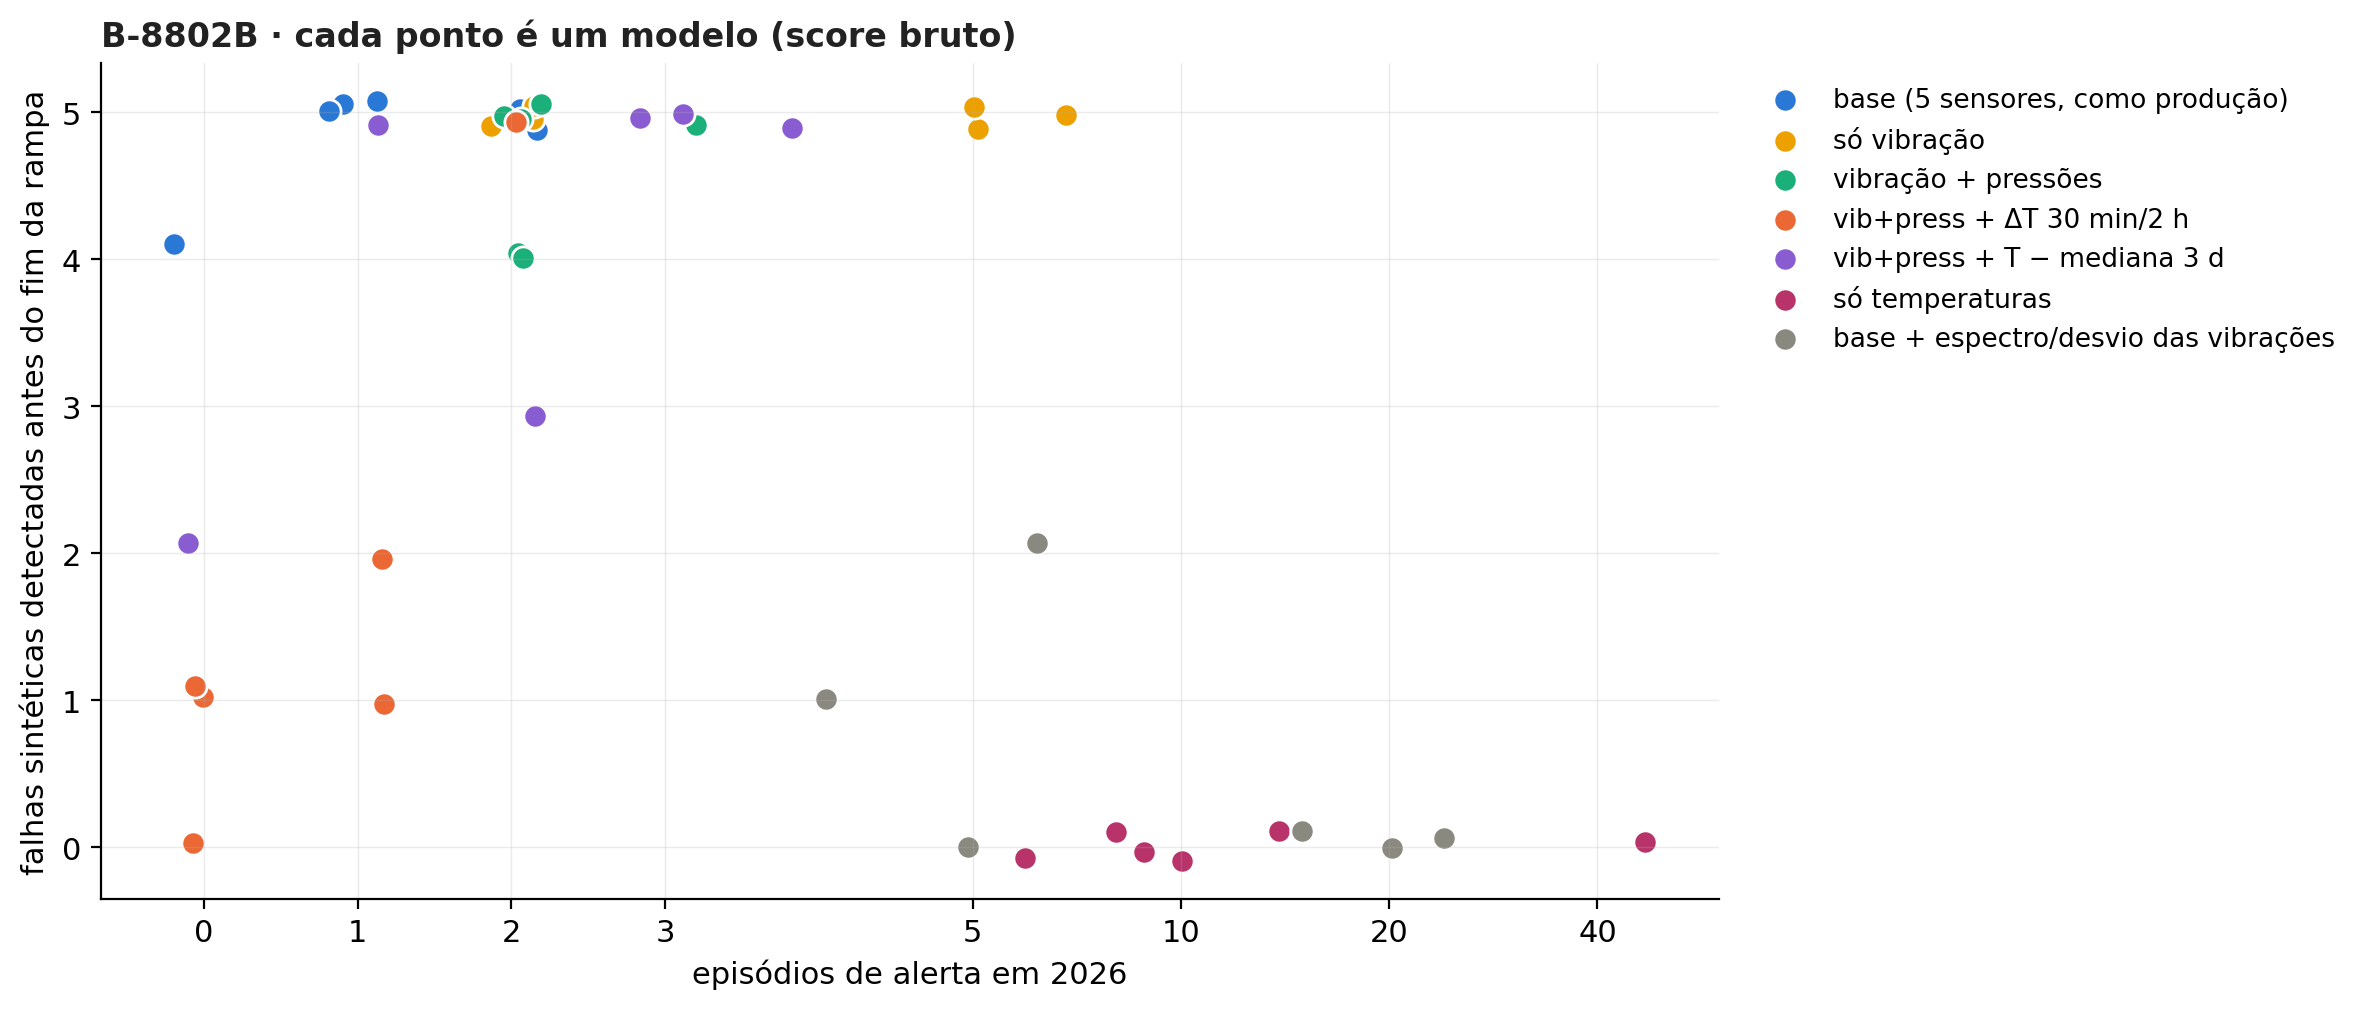

In [6]:
gb = g[g.modo == "bruto"].copy(); gb["sint_ok"] = gb.s100_ok + gb.s50_ok
fig, ax = plt.subplots(figsize=(12, 5.2))
rng = np.random.default_rng(0)
for v in NOMES:
    d = gb[gb.variante == v]
    ax.scatter(d.episodios_2026 + rng.uniform(-0.2, 0.2, len(d)), d.sint_ok + rng.uniform(-0.12, 0.12, len(d)),
               s=70, color=CORES[v], edgecolor="white", lw=1, label=NOMES[v])
ax.set_xscale("symlog", linthresh=5)
ax.set_xticks([0, 1, 2, 3, 5, 10, 20, 40]); ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("episódios de alerta em 2026"); ax.set_ylabel("falhas sintéticas detectadas antes do fim da rampa")
ax.legend(fontsize=9.5, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
estilo(ax, "B-8802B · cada ponto é um modelo (score bruto)")
fig.tight_layout()

## 6. E uma falha só térmica?

Tirar a temperatura do modelo só seria um problema se ele hoje percebesse uma falha térmica. Teste: a parte térmica da
assinatura de 2022 (mancal LA +6,7 °C, e os outros mancais) em rampa de 48 h, sem mudar vibração nem pressões, a 1× e a
2× (+13,4 °C), nas 3 datas válidas. Contagem: detectados / casos válidos, somando os 6 modelos.

In [7]:
linhas = {}
for (v, m), d in te.groupby(["variante", "modo"]):
    r = {}
    for k in (1, 2):
        c = [x for x in d if x.startswith(f"termica{k}x")]
        r[f"+{6.7 * k:.1f} °C: detecta"] = f"{int((d[c] > -99).sum().sum())}/{int(d[c].notna().sum().sum())}"
        r[f"+{6.7 * k:.1f} °C: antes do fim da rampa"] = int((d[c] > 0).sum().sum())
    linhas[f"{NOMES[v]} · {m}"] = r
pd.DataFrame(linhas).T

,+6.7 °C: detecta,+6.7 °C: antes do fim da rampa,+13.4 °C: detecta,+13.4 °C: antes do fim da rampa
"base (5 sensores, como produção) · bruto",0/18,0,1/18,0
"base (5 sensores, como produção) · suave",0/17,0,5/17,0
vib+press + ΔT 30 min/2 h · bruto,0/18,0,0/18,0
vib+press + ΔT 30 min/2 h · suave,0/18,0,0/18,0
vib+press + T − mediana 3 d · bruto,0/18,0,0/18,0
vib+press + T − mediana 3 d · suave,0/18,0,2/18,0
só vibração · bruto,0/18,0,0/18,0
só vibração · suave,0/16,0,0/16,0
vibração + pressões · bruto,0/18,0,0/18,0
vibração + pressões · suave,0/18,0,0/18,0


**Leitura:** nem o modelo de produção (base) percebe uma falha só térmica: 0 de 18 a +6,7 °C e quase nada a
+13,4 °C. A temperatura de 2025 varia ~20 °C entre estações, então uma subida de 7–13 °C em 2 dias cabe no "normal"
do VAE. Hoje a temperatura entra no modelo quase só como **fonte de erro sazonal**, não como sensibilidade. Uma falha
térmica precisa de um detector próprio (ex.: o resíduo de temperatura M8 do monitor, ou uma regra de taxa de subida).

## 7. Conclusões

**O que deu certo**
1. **Tirar a temperatura do VAE (vibração + pressões)** é o melhor resultado: o erro fica mais estável em 2026 (1,2× em
   vez de 1,8× em abr–ago; em ago/26 todas sobem por causa da pressão de descarga), os 6 modelos alertam na âncora de 17/01 (base: 4/6), 0 alerta em jun–ago/26, falha de 2022 com 2,1 dias e a
   sintética igual ao base. É também o grupo mais **consistente entre sementes** — o problema recorrente dos retreinos.
2. **A temperatura não traz sensibilidade hoje** (seção 6): sai do modelo e vai para um detector próprio.
3. **Temperatura transformada** (ΔT em 30 min/2 h, ou T − mediana de 3 dias) também estabiliza o erro (1,1×), mas não
   ganha nada sobre vibração + pressões; o ΔT sozinho com score bruto até perde sintética.
4. **Suavizar o score** (mediana 1 h) deixa a curva legível; para reduzir alarme precisa de outra regra de limiar.

**O que não deu certo**
- **Só temperaturas**: cego para a falha (0/18) e alerta o tempo todo em 2026 (erro 3,9×).
- **Espectro/desvio das vibrações**: piora (erro 2,8×, até 40 episódios). Com médias de 5 min o "espectro" vê só
  oscilações lentas do processo, não a vibração mecânica.
- **Só vibração**: estável (1,07×) e sensível, mas alerta mais em jan/26 (episódios em 10–12/01) e é menos consistente
  na âncora; as pressões ajudam o modelo a saber o regime.
- Antes (task ea9fd4cc): a **diferença mancal − motor** piorou a sintética.

**Cuidados:** 2026 não tem rótulo completo (episódios ≠ falsos confirmados); os episódios de 10–12/01/2026 aparecem nos
modelos de vibração e também no detector "C1 só vibração" do experimento de 17/10 — vale perguntar à operação. A
sintética usa a assinatura de uma única falha (2022, acoplamento), que é dominada por vibração.

**Próximo passo sugerido:** retreinar "vibração + pressões" com o pipeline completo (grade 4 cfg × 3 sementes + bateria)
e acompanhar a temperatura por fora (M8 ou regra de taxa).